In [1]:
import geopandas as gpd
import pandas as pd

# Load the city boundary and hexagons
city = gpd.read_file("../data/processed/city_boundary.gpkg")
hexes = gpd.read_file("../data/processed/hex_features.gpkg")


def to_points(gdf, label, dedupe_m):
    """Convert features to named points and remove duplicates
    (same name within dedupe_m metres)."""
    gdf = gdf.to_crs(epsg=32617)
    gdf = gdf[gdf["name"].notna()].copy()
    gdf["geometry"] = gdf.geometry.centroid
    gdf = gdf[["name", "geometry"]].reset_index(drop=True)

    buffers = gdf.copy()
    buffers["geometry"] = gdf.buffer(dedupe_m)
    near = gpd.sjoin(gdf, buffers, predicate="within")
    dupes = near[(near.index < near["index_right"]) & (near["name_left"] == near["name_right"])]
    gdf = gdf.drop(dupes["index_right"].unique()).reset_index(drop=True)

    gdf["category"] = label
    return gdf

In [2]:
GTFS = "../data/raw/ttc_gtfs/"

routes = pd.read_csv(GTFS + "routes.txt")

# route_type 1 = subway. Lines 5 and 6 (LRT) are route_type 0, like streetcars,
# so pick them out by line number instead.
rapid = routes[(routes["route_type"] == 1) |
               (routes["route_short_name"].astype(str).isin(["5", "6"]))]

rapid[["route_short_name", "route_long_name", "route_type"]]

,route_short_name,route_long_name,route_type
0,1,Line 1 (Yonge-University),1
66,2,Line 2 (Bloor - Danforth),1
127,4,Line 4 (Sheppard),1
144,5,Line 5 Eglinton,0
164,6,Line 6 Finch West,0


In [3]:
# GTFS links routes -> trips -> stop_times -> stops, so follow that chain
trips = pd.read_csv(GTFS + "trips.txt", usecols=["route_id", "trip_id"])
rapid_trip_ids = trips.loc[trips["route_id"].isin(rapid["route_id"]), "trip_id"]

stop_times = pd.read_csv(GTFS + "stop_times.txt", usecols=["trip_id", "stop_id"])
rapid_stop_ids = stop_times.loc[stop_times["trip_id"].isin(rapid_trip_ids), "stop_id"].unique()

stops = pd.read_csv(GTFS + "stops.txt")
rapid_stops = stops[stops["stop_id"].isin(rapid_stop_ids)].copy()
print("Platform stops:", len(rapid_stops))
rapid_stops["stop_name"].head(10)

Platform stops: 234


7995                Finch Station - Southbound Platform
7996    North York Centre Station - Southbound Platform
7997       Sheppard-Yonge Station - Southbound Platform
7998           York Mills Station - Southbound Platform
7999             Lawrence Station - Southbound Platform
8000             Eglinton Station - Southbound Platform
8001           Davisville Station - Southbound Platform
8002             St Clair Station - Southbound Platform
8003           Summerhill Station - Southbound Platform
8004             Rosedale Station - Southbound Platform
Name: stop_name, dtype: str

Stations: 153


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

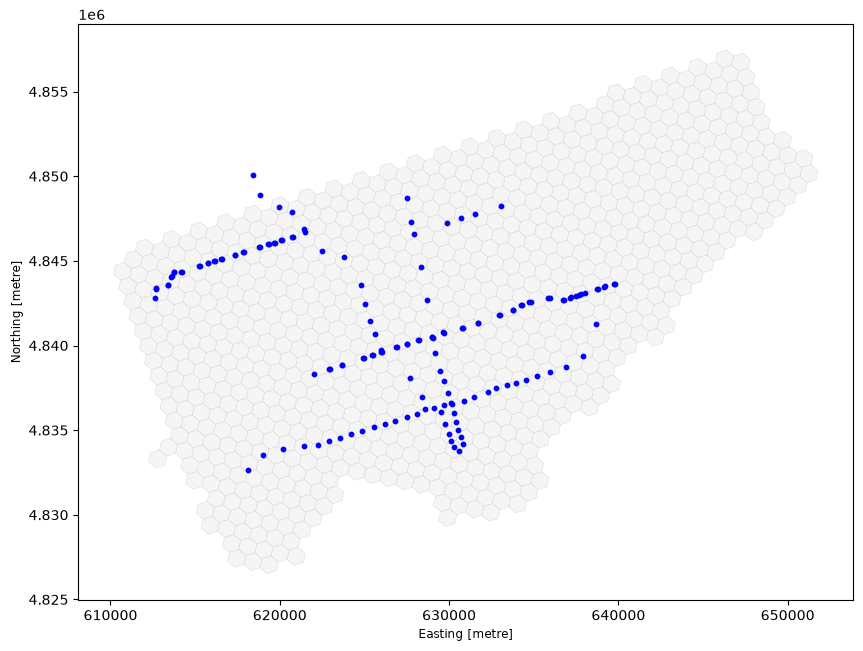

In [4]:
# Each station has several platform stops (e.g. "X Station - Northbound Platform"),
# so strip the platform part and average their locations
rapid_stops["station"] = rapid_stops["stop_name"].str.split(" - ").str[0].str.strip()
st = rapid_stops.groupby("station")[["stop_lat", "stop_lon"]].mean().reset_index()

stations = gpd.GeoDataFrame(
    {"name": st["station"], "category": "station"},
    geometry=gpd.points_from_xy(st["stop_lon"], st["stop_lat"]),
    crs="EPSG:4326",
).to_crs(epsg=32617)

print("Stations:", len(stations))
ax = hexes.plot(color="whitesmoke", edgecolor="lightgrey", linewidth=0.3, figsize=(10, 10))
stations.plot(ax=ax, color="blue", markersize=10)